In [1]:
import pandas as pd
print(pd.__version__)

3.0.6


In [2]:
import pandas as pd
df = pd.read_csv("../data/demanddata_2022.csv")
df.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW
0,01-JAN-2022,1,21940,23275,20513,2713,6527,0,14008,0,...,-181,-4,586,320,384,-100,210,0,0,0
1,01-JAN-2022,2,22427,23489,21021,2755,6527,0,14008,0,...,-181,-4,583,320,403,-104,176,0,0,0
2,01-JAN-2022,3,21896,23672,20619,2930,6527,0,14008,0,...,-164,-4,567,320,440,-4,-205,0,0,0
3,01-JAN-2022,4,20693,23272,19615,3090,6527,0,14008,0,...,-170,-4,444,320,387,-6,-283,0,0,0
4,01-JAN-2022,5,19481,23958,18545,3161,6527,0,14008,0,...,-753,-4,-383,320,476,-561,-686,0,0,0


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   SETTLEMENT_DATE            17520 non-null  str  
 1   SETTLEMENT_PERIOD          17520 non-null  int64
 2   ND                         17520 non-null  int64
 3   TSD                        17520 non-null  int64
 4   ENGLAND_WALES_DEMAND       17520 non-null  int64
 5   EMBEDDED_WIND_GENERATION   17520 non-null  int64
 6   EMBEDDED_WIND_CAPACITY     17520 non-null  int64
 7   EMBEDDED_SOLAR_GENERATION  17520 non-null  int64
 8   EMBEDDED_SOLAR_CAPACITY    17520 non-null  int64
 9   NON_BM_STOR                17520 non-null  int64
 10  PUMP_STORAGE_PUMPING       17520 non-null  int64
 11  IFA_FLOW                   17520 non-null  int64
 12  IFA2_FLOW                  17520 non-null  int64
 13  BRITNED_FLOW               17520 non-null  int64
 14  MOYLE_FLOW                 17520 

In [5]:
#SETTLEMENT_DATE is text so we want to convert it to a real date.
df["date"] = pd.to_datetime(df["SETTLEMENT_DATE"], format = "%d-%b-%Y")
#Period 1 is the first half hour of the day, each period is 30 minutes long
#Doing maths in UTC avoids problems on days where the clock changes
day_start = df["date"].dt.tz_localize("Europe/London").dt.tz_convert("UTC")
df["timestamp_utc"] = day_start + pd.to_timedelta((df["SETTLEMENT_PERIOD"] - 1) * 30, unit="min")

df[["SETTLEMENT_DATE", "SETTLEMENT_PERIOD", "timestamp_utc", "ND"]].head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,timestamp_utc,ND
0,01-JAN-2022,1,2022-01-01 00:00:00+00:00,21940
1,01-JAN-2022,2,2022-01-01 00:30:00+00:00,22427
2,01-JAN-2022,3,2022-01-01 01:00:00+00:00,21896
3,01-JAN-2022,4,2022-01-01 01:30:00+00:00,20693
4,01-JAN-2022,5,2022-01-01 02:00:00+00:00,19481


In [6]:
print("Duplicate timestamps:", df["timestamp_utc"].duplicated().sum())
print()
print(df["timestamp_utc"].sort_values().diff().value_counts())
print()
print(df.groupby("date").size().value_counts())

Duplicate timestamps: 0

timestamp_utc
0 days 00:30:00    17519
Name: count, dtype: int64

48    363
46      1
50      1
Name: count, dtype: int64


In [7]:
files = [
    "../data/demanddata_2022.csv",
    "../data/demanddata_2023.csv",
    "../data/demanddata_2024.csv",
]

raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
raw.shape

(52608, 22)

In [9]:
# The yearly files use different date formats (e.g. "01-JAN-2022" vs "01-Jan-23"),
# so let pandas infer the format row by row.
raw["date"] = pd.to_datetime(raw["SETTLEMENT_DATE"], format="mixed", dayfirst=True)

day_start = raw["date"].dt.tz_localize("Europe/London").dt.tz_convert("UTC")
raw["timestamp_utc"] = day_start + pd.to_timedelta((raw["SETTLEMENT_PERIOD"] - 1) * 30, unit="min")

demand = (
    raw[["timestamp_utc", "date", "SETTLEMENT_PERIOD", "ND"]]
    .sort_values("timestamp_utc")
    .set_index("timestamp_utc")
)

demand.head()


,date,SETTLEMENT_PERIOD,ND
timestamp_utc,,,
2022-01-01 00:00:00+00:00,2022-01-01,1,21940
2022-01-01 00:30:00+00:00,2022-01-01,2,22427
2022-01-01 01:00:00+00:00,2022-01-01,3,21896
2022-01-01 01:30:00+00:00,2022-01-01,4,20693
2022-01-01 02:00:00+00:00,2022-01-01,5,19481


In [10]:
print("Rows:", len(demand))
print("Duplicate timestamps:", demand.index.duplicated().sum())
print()
print(demand.index.to_series().diff().value_counts())
print()
print(demand.groupby("date").size().value_counts())

Rows: 52608
Duplicate timestamps: 0

timestamp_utc
0 days 00:30:00    52607
Name: count, dtype: int64

48    1090
46       3
50       3
Name: count, dtype: int64


Matplotlib is building the font cache; this may take a moment.


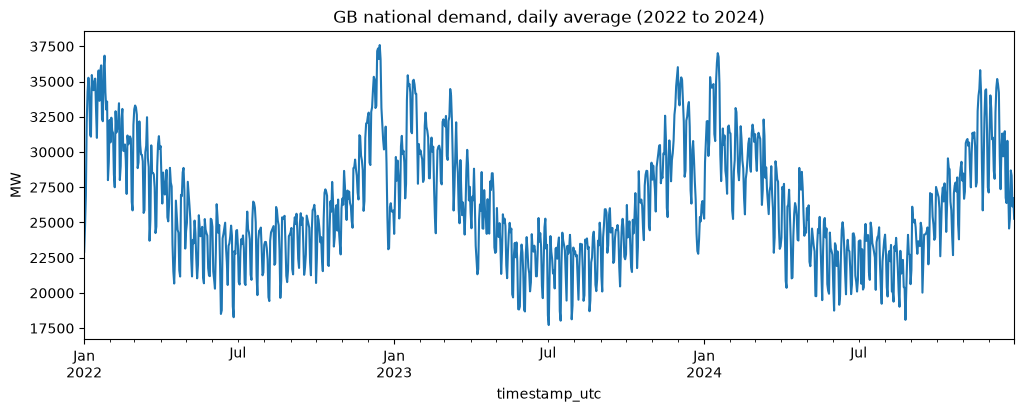

In [11]:
import matplotlib.pyplot as plt

daily = demand["ND"].resample("D").mean()

daily.plot(figsize=(12, 4))
plt.title("GB national demand, daily average (2022 to 2024)")
plt.ylabel("MW")
plt.show()

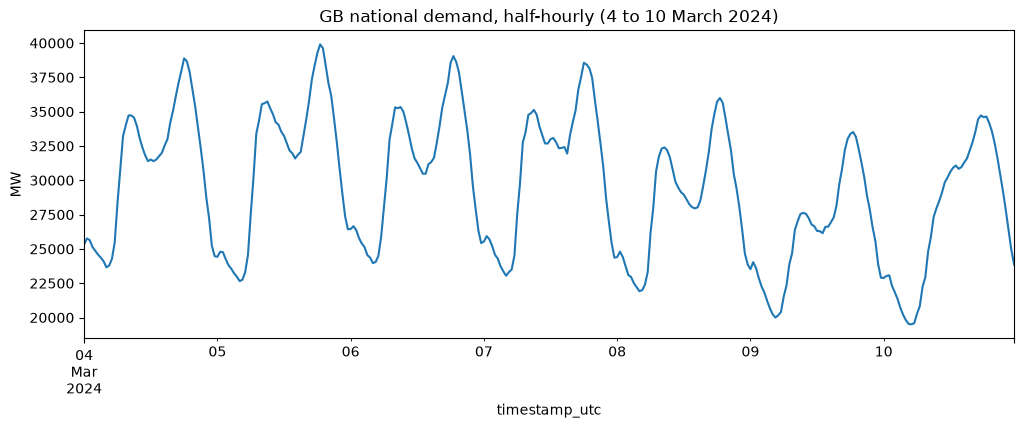

In [12]:
week = demand.loc["2024-03-04":"2024-03-10", "ND"]

week.plot(figsize=(12, 4))
plt.title("GB national demand, half-hourly (4 to 10 March 2024)")
plt.ylabel("MW")
plt.show()